# 01 - Data Exploration

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load data

In [35]:
months = ["202512", "202601", "202602", "202603", "202604", "202605"]
files = [f"california/CRMLSSold{m}.csv" for m in months]

df = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
df.shape

(124404, 78)

In [36]:
# Filter as required
df = df[(df["PropertyType"] == "Residential") & (df["PropertySubType"] == "SingleFamilyResidence")]
df.shape

(61727, 78)

In [37]:
# Grab the columns of interest
cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet"]
df[cols].describe()

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet
count,6.172700e+04,61697.000000,61727.000000,61726.000000,6.064600e+04
mean,1.340106e+06,2055.552918,3.498437,2.644801,3.859489e+05
std,7.307629e+06,1037.243701,0.966684,1.135026,1.843401e+07
min,1.750000e+00,0.000000,0.000000,0.000000,0.000000e+00
25%,6.200000e+05,1386.000000,3.000000,2.000000,5.663000e+03
50%,8.900000e+05,1826.000000,3.000000,2.000000,7.263500e+03
75%,1.425000e+06,2455.000000,4.000000,3.000000,1.045400e+04
max,7.960000e+08,23314.000000,22.000000,22.000000,1.897474e+09


In [38]:
# Get the number of NA values for each column
df[cols].isna().sum()

ClosePrice                  0
LivingArea                 30
BedroomsTotal               0
BathroomsTotalInteger       1
LotSizeSquareFeet        1081
dtype: int64

## Histograms

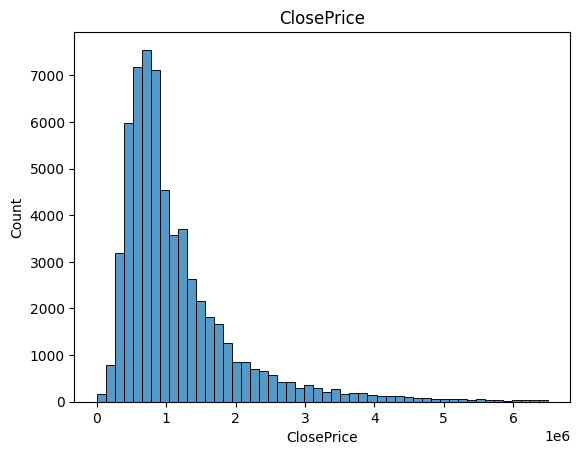

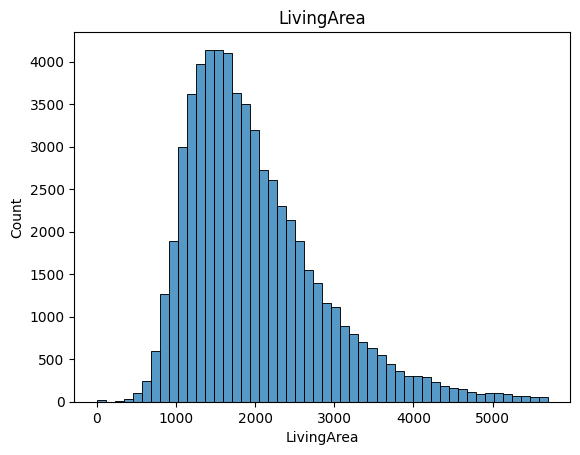

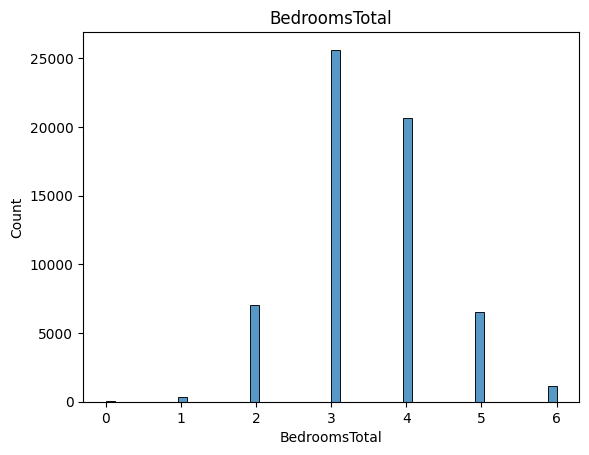

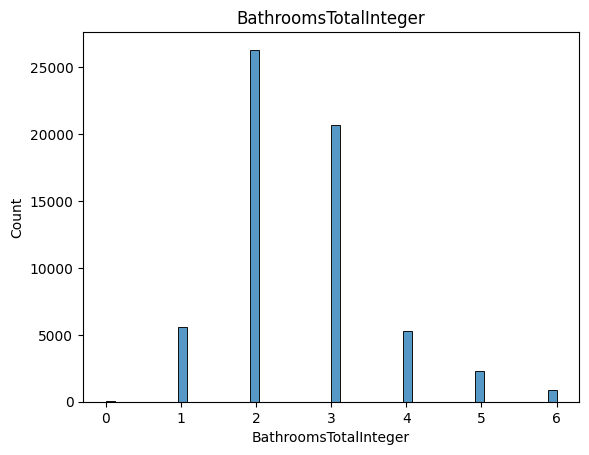

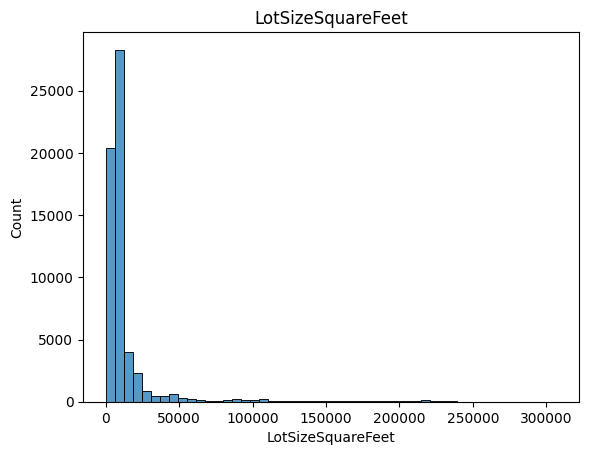

In [39]:
# Create histograms, cap them at 99th percentile 
for col in cols:
    plt.figure()
    sns.histplot(df[df[col] <= df[col].quantile(0.99)][col], bins=50).set_title(col)
    plt.show()

## Pairplot

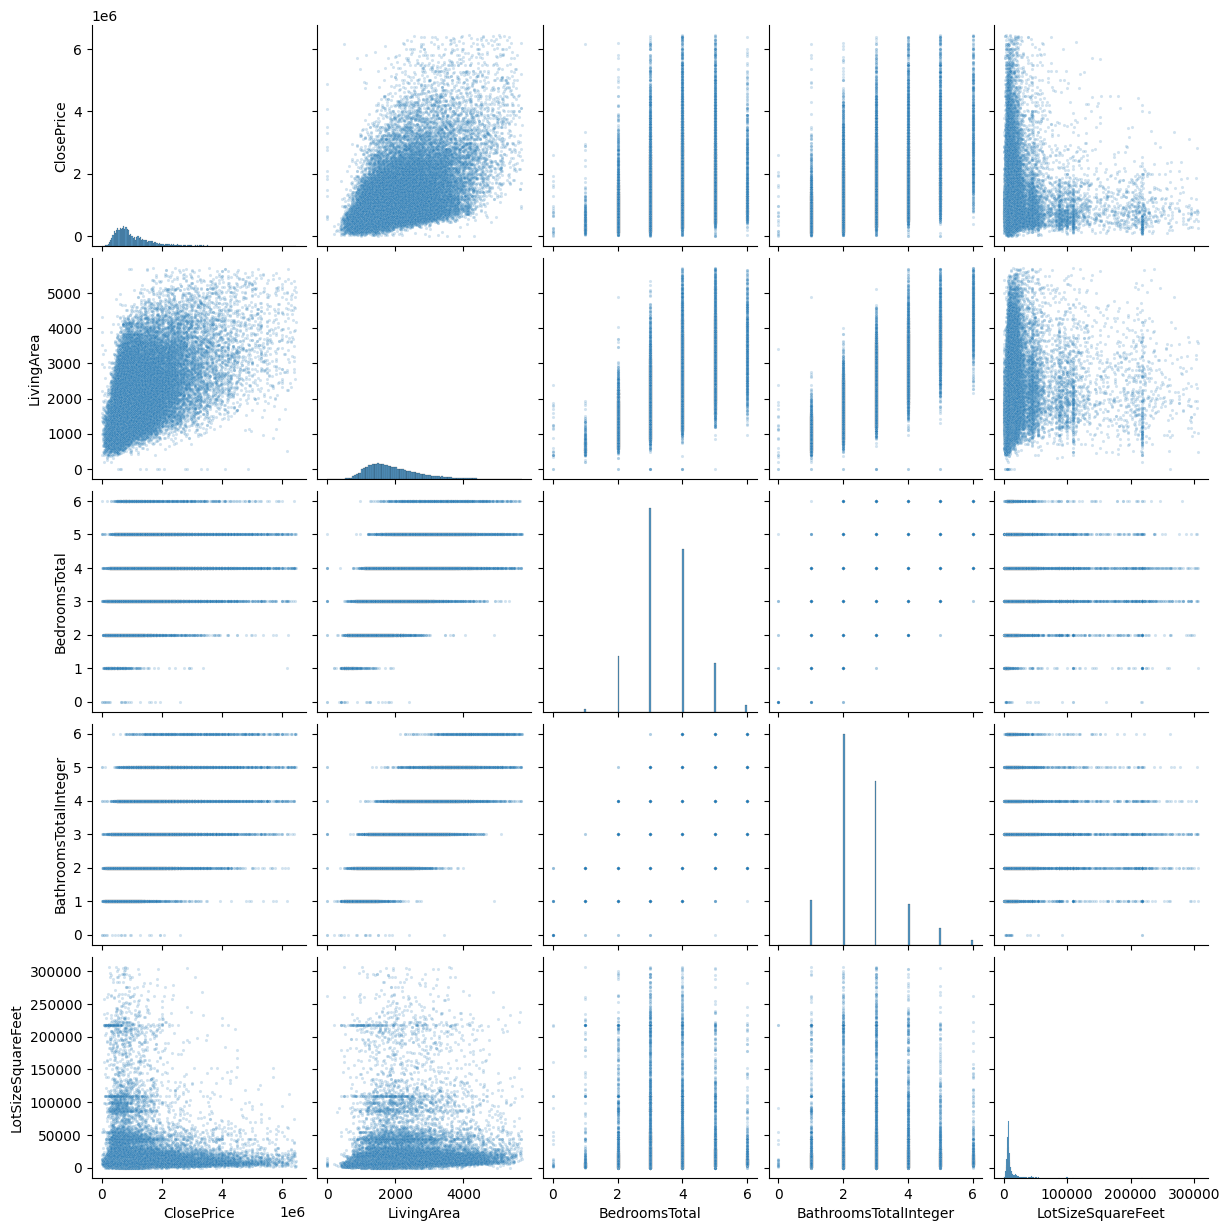

In [40]:
sub = df[cols].dropna()
sub = sub[(sub <= sub.quantile(0.99)).all(axis=1)]
sns.pairplot(sub, plot_kws={"alpha": 0.2, "s": 5})
plt.show()